# Part 1

this is car part segemntation using github repo
BY Sakheen

https://github.com/dsmlr/Car-Parts-Segmentation.git

In [1]:
!git clone https://github.com/dsmlr/Car-Parts-Segmentation.git


Cloning into 'Car-Parts-Segmentation'...
remote: Enumerating objects: 564, done.
remote: Counting objects: 100% (564/564), done.
remote: Compressing objects: 100% (549/549), done.
remote: Total 564 (delta 27), reused 548 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (564/564), 24.04 MiB | 19.00 MiB/s, done.
Resolving deltas: 100% (27/27), done.


In [2]:
%cd Car-Parts-Segmentation


/content/Car-Parts-Segmentation


In [5]:
%matplotlib inline

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
import requests
from pycocotools.coco import COCO

import skimage.io as io

## Dataset Exploration


#### 1) Initialize the COCO api for instance annotations

In [6]:
data_dir='./testset'
annotation_file='{}/annotations.json'.format(data_dir)

coco=COCO(annotation_file)

loading annotations into memory...
Done (t=0.02s)
creating index...
index created!


#### 2) Load the categories in a variable



In [9]:
catIDs = coco.getCatIds()
cats = coco.loadCats(catIDs)
catIDs

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

In [8]:
cats

[{'id': 1,
  'name': '_background_',
  'supercategory': '',
  'color': '#93a51d',
  'metadata': {},
  'keypoint_colors': []},
 {'id': 2,
  'name': 'back_bumper',
  'supercategory': '',
  'color': '#dd8271',
  'metadata': {},
  'keypoint_colors': []},
 {'id': 3,
  'name': 'back_glass',
  'supercategory': '',
  'color': '#dda950',
  'metadata': {},
  'keypoint_colors': []},
 {'id': 4,
  'name': 'back_left_door',
  'supercategory': '',
  'color': '#ea72a3',
  'metadata': {},
  'keypoint_colors': []},
 {'id': 5,
  'name': 'back_left_light',
  'supercategory': '',
  'color': '#51fadb',
  'metadata': {},
  'keypoint_colors': []},
 {'id': 6,
  'name': 'back_right_door',
  'supercategory': '',
  'color': '#ca0f11',
  'metadata': {},
  'keypoint_colors': []},
 {'id': 7,
  'name': 'back_right_light',
  'supercategory': '',
  'color': '#911ea4',
  'metadata': {},
  'keypoint_colors': []},
 {'id': 8,
  'name': 'front_bumper',
  'supercategory': '',
  'color': '#2367ef',
  'metadata': {},
  'keypoi

#### 3) Explore result of cats



In [10]:
print('ID \t: Class Name')
print("-----------------")
for i in cats:
    print('{}\t: {}'.format(i['id'], i['name']))

ID 	: Class Name
-----------------
1	: _background_
2	: back_bumper
3	: back_glass
4	: back_left_door
5	: back_left_light
6	: back_right_door
7	: back_right_light
8	: front_bumper
9	: front_glass
10	: front_left_door
11	: front_left_light
12	: front_right_door
13	: front_right_light
14	: hood
15	: left_mirror
16	: right_mirror
17	: tailgate
18	: trunk
19	: wheel


#### 4) Load images



In [12]:
imgIds = coco.getImgIds()
images = coco.loadImgs(imgIds)

#### 5) Pick one random image and its annotations



In [13]:
random_imgId = imgIds[np.random.randint(0,len(imgIds))]
img = coco.loadImgs(random_imgId)[0]
img

{'id': 411,
 'dataset_id': 3,
 'category_ids': [],
 'path': 'JPEGImages/car5.jpg',
 'width': 512,
 'height': 512,
 'file_name': 'car5.jpg',
 'annotated': False,
 'annotating': [],
 'num_annotations': 0,
 'metadata': {},
 'deleted': False,
 'milliseconds': 0,
 'events': [],
 'regenerate_thumbnail': False}

#### 6) Show picked image



In [1]:
I = io.imread('{}/{}'.format(data_dir,img['path']))/255.0


NameError: name 'io' is not defined

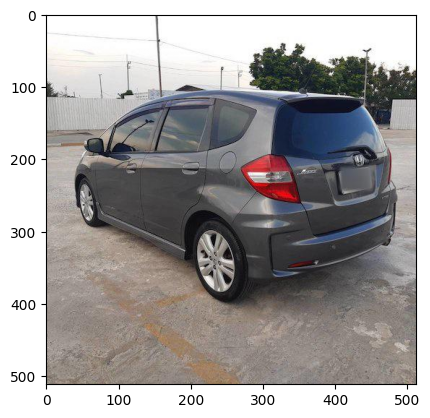

In [15]:
plt.imshow(I)


#### 7) Load its annotations and show picked image with overlay of annotation masks



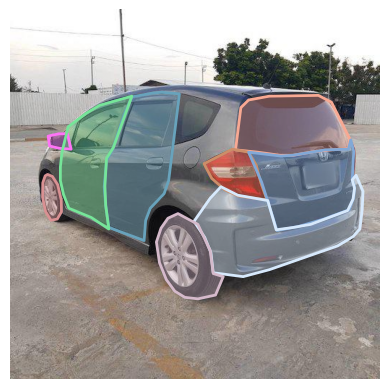

In [16]:
# Load and display instance annotations
plt.imshow(I)
plt.axis('off')

annIds = coco.getAnnIds(imgIds=img['id'], iscrowd=None)
anns = coco.loadAnns(annIds)
coco.showAnns(anns)

Data in variable anns



In [17]:
anns

[{'id': 3657,
  'image_id': 411,
  'category_id': 15,
  'segmentation': [[84.2,
    193.1,
    68.3,
    192.0,
    54.4,
    188.8,
    52.3,
    175.0,
    67.2,
    171.8,
    78.9,
    171.8]],
  'area': 527,
  'bbox': [52.0, 172.0, 32.0, 21.0],
  'iscrowd': False,
  'isbbox': False,
  'color': '#7fe18f',
  'metadata': {}},
 {'id': 3658,
  'image_id': 411,
  'category_id': 3,
  'segmentation': [[311.9,
    194.1,
    319.3,
    135.6,
    330.0,
    125.0,
    358.7,
    119.7,
    426.8,
    118.6,
    444.9,
    128.2,
    470.4,
    179.2,
    468.3,
    192.0,
    421.5,
    196.3,
    391.7,
    201.6,
    373.6,
    201.6,
    342.7,
    197.3]],
  'area': 10867,
  'bbox': [312.0, 119.0, 158.0, 83.0],
  'iscrowd': False,
  'isbbox': False,
  'color': '#24b701',
  'metadata': {}},
 {'id': 3659,
  'image_id': 411,
  'category_id': 5,
  'segmentation': [[307.6,
    193.1,
    268.3,
    213.3,
    278.9,
    233.5,
    297.0,
    249.4,
    316.1,
    258.0,
    355.5,
    263.3

#### 8) Get the annotation categories of picked image



In [18]:
picked_image_annIDs = [i['category_id'] for i in anns]
picked_image_cats = coco.loadCats(picked_image_annIDs)

In [19]:
print('ID \t: Class Name')
print("-----------------")
for i in picked_image_cats:
    print('{} \t: {}'.format(i['id'], i['name']))

ID 	: Class Name
-----------------
15 	: left_mirror
3 	: back_glass
5 	: back_left_light
17 	: tailgate
2 	: back_bumper
4 	: back_left_door
10 	: front_left_door
19 	: wheel
19 	: wheel


# Part2

Add new Rim

Step 1: Extract the Rim Mask
Use the segmentation annotations (anns) to create a mask for the rims:

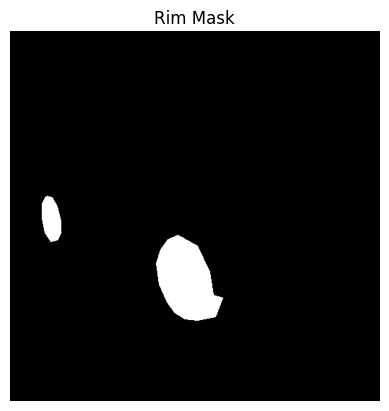

In [21]:
import numpy as np
import cv2
from matplotlib import pyplot as plt

# Create an empty mask the size of the image
rim_mask = np.zeros((img['height'], img['width']), dtype=np.uint8)

# Extract the segmentation for rims (category_id = 19)
for ann in anns:
    if ann['category_id'] == 19:  # Rim category
        segmentation = np.array(ann['segmentation'][0]).reshape((-1, 2))
        cv2.fillPoly(rim_mask, [segmentation.astype(np.int32)], color=1)

plt.imshow(rim_mask, cmap='gray')
plt.axis('off')
plt.title("Rim Mask")
plt.show()


Step 2: Load and Transform the Rim Replacement Image
Replace the rims with a new design:


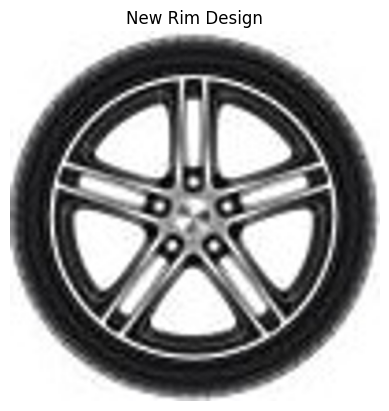

In [26]:
from PIL import Image

# Load the new rim design image
new_rim = Image.open('/content/r4.jpg')
new_rim = new_rim.resize((img['width'], img['height']))  # Resize to image dimensions

# Convert to numpy array
new_rim_array = np.array(new_rim)

# Ensure the new rim image is compatible with the mask
if len(new_rim_array.shape) == 2:  # Grayscale to RGB
    new_rim_array = np.stack([new_rim_array]*3, axis=-1)

plt.imshow(new_rim)
plt.axis('off')
plt.title("New Rim Design")
plt.show()


Adjust New Rims to Fit Properly

Step 1: Extract the Rim Bounding Box

Find the bounding box around the rim mask:

In [28]:
# Get the bounding box of the rim mask
x, y, w, h = cv2.boundingRect(rim_mask)

# Crop the new rim design to fit the bounding box
new_rim_cropped = new_rim.resize((w, h))
new_rim_array = np.array(new_rim_cropped)


Step 2: Replace the Rim Area

Replace the rim area within the bounding box:

In [29]:
# Create a blank image with the same size as the original
rim_overlay = np.zeros_like(original_image)

# Place the resized rim design in the bounding box
rim_overlay[y:y+h, x:x+w] = new_rim_array

# Combine the original image and the overlay using the rim mask
rim_mask_expanded = np.stack([rim_mask]*3, axis=-1)  # Expand mask to 3 channels
output_image = np.where(rim_mask_expanded, rim_overlay, original_image)


Step 3: Perspective Transform (Optional)

If the new rim doesn't match the perspective, apply a transformation

In [32]:
# Convert rim segmentation to a NumPy array
rim_points = np.array(segmentation).reshape((-1, 2))  # Replace `segmentation` with actual segmentation data

# Compute the bounding box or convex hull for simplicity
from scipy.spatial import ConvexHull
hull = ConvexHull(rim_points)

# Use the convex hull's vertices as the corners
quad_points = rim_points[hull.vertices][:4]


In [33]:
if len(quad_points) != 4:
    # Find bounding box as a fallback
    x_min, y_min = np.min(rim_points, axis=0)
    x_max, y_max = np.max(rim_points, axis=0)
    quad_points = np.array([
        [x_min, y_min],
        [x_max, y_min],
        [x_max, y_max],
        [x_min, y_max]
    ])


In [34]:
# Ensure the rim points and new rim points have 4 points
quad_points = quad_points.astype(np.float32)
new_rim_points = np.array([[0, 0], [w, 0], [w, h], [0, h]], dtype=np.float32)

# Calculate the perspective transform matrix
matrix = cv2.getPerspectiveTransform(new_rim_points, quad_points)

# Warp the new rim image to fit the rim mask
new_rim_warped = cv2.warpPerspective(new_rim_array, matrix, (original_image.shape[1], original_image.shape[0]))

# Apply the warped rim to the original image
output_image = np.where(rim_mask_expanded, new_rim_warped, original_image)


Step 3: Apply the New Rim Design to the Original Image
Blend the new rim into the original car image where the rim mask is 1:

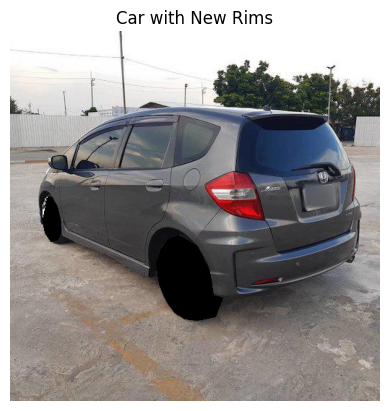

In [35]:
# # Blend the original image with the new rim design
# original_image = np.array(Image.open(f"{data_dir}/{img['path']}"))

# # Ensure compatibility of the mask with the image
# rim_mask_3d = np.stack([rim_mask]*3, axis=-1)

# # Replace the rims in the original image
# output_image = np.where(rim_mask_3d, new_rim_array, original_image)

# Display the result
plt.imshow(output_image)
plt.axis('off')
plt.title("Car with New Rims")
plt.show()


Step 4: Save the Result
Save the modified image if needed:

In [ ]:
# # Convert back to PIL Image and save
# output_image_pil = Image.fromarray(output_image)
# output_image_pil.save('/path/to/output_image.jpg')


# Next try

## Workin good for one rim

In [36]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
from skimage.io import imread


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


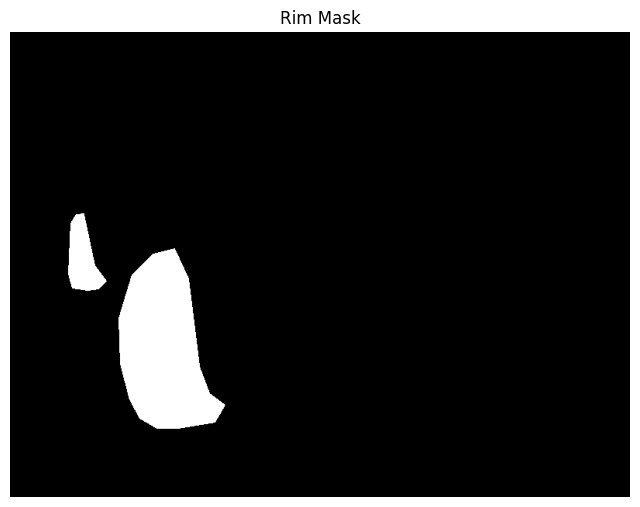

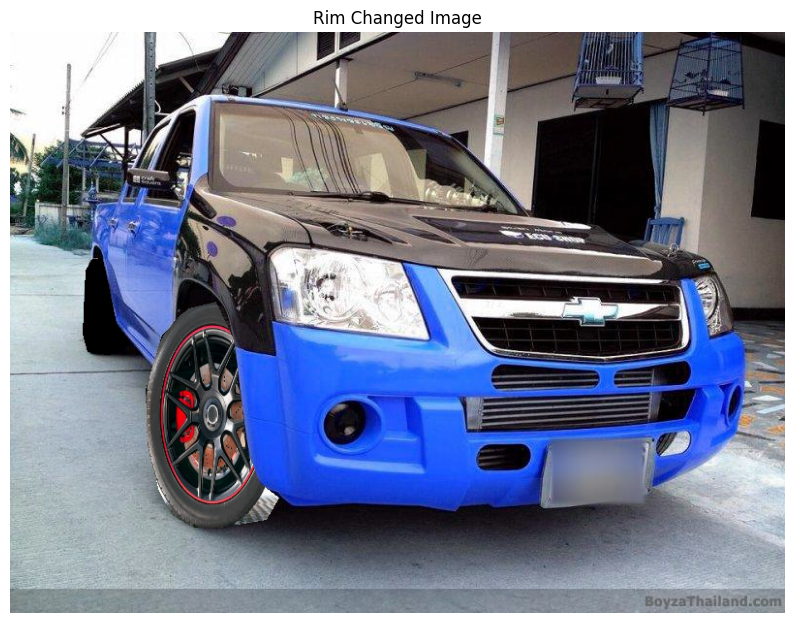

In [38]:

# Initialize COCO and load dataset
data_dir = './testset'
annotation_file = f'{data_dir}/annotations.json'
coco = COCO(annotation_file)

# Get the category ID for rims
rim_category_id = 19

# Load a random image with rim annotations
img_ids = coco.getImgIds(catIds=[rim_category_id])
if not img_ids:
    raise ValueError("No images found with rims.")
random_img_id = img_ids[np.random.randint(len(img_ids))]
img_info = coco.loadImgs(random_img_id)[0]
image_path = f"{data_dir}/{img_info['path']}"
original_image = imread(image_path)

# Get annotations for the selected image
ann_ids = coco.getAnnIds(imgIds=[img_info['id']], catIds=[rim_category_id], iscrowd=None)
anns = coco.loadAnns(ann_ids)

# Create a blank mask
rim_mask = np.zeros((img_info['height'], img_info['width']), dtype=np.uint8)

# Draw the rim masks using segmentation polygons
for ann in anns:
    for seg in ann['segmentation']:
        poly = np.array(seg).reshape((-1, 2))
        cv2.fillPoly(rim_mask, [np.int32(poly)], 255)

# Display the rim mask
plt.figure(figsize=(8, 8))
plt.imshow(rim_mask, cmap='gray')
plt.axis('off')
plt.title("Rim Mask")
plt.show()

# Load new rim image
new_rim_image = cv2.imread("/content/gwagon1.jpg")

# Find contours in the rim mask
contours, _ = cv2.findContours(rim_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
if not contours:
    raise ValueError("No contours found in the rim mask.")

# Get the largest contour (assumes it corresponds to the rim)
rim_contour = max(contours, key=cv2.contourArea)

# Approximate the rim contour to a quadrilateral
epsilon = 0.02 * cv2.arcLength(rim_contour, True)
rim_quad = cv2.approxPolyDP(rim_contour, epsilon, True)

# If not exactly 4 points, fallback to bounding box
if len(rim_quad) != 4:
    x, y, w, h = cv2.boundingRect(rim_contour)
    rim_quad = np.array([
        [[x, y]],
        [[x + w, y]],
        [[x + w, y + h]],
        [[x, y + h]]
    ], dtype=np.float32)
else:
    rim_quad = rim_quad.astype(np.float32)

# Define target points for the new rim image
new_rim_h, new_rim_w = new_rim_image.shape[:2]
new_rim_points = np.array([
    [0, 0],
    [new_rim_w - 1, 0],
    [new_rim_w - 1, new_rim_h - 1],
    [0, new_rim_h - 1]
], dtype=np.float32)

# Compute perspective transform matrix
transform_matrix = cv2.getPerspectiveTransform(new_rim_points, rim_quad.reshape(4, 2))

# Warp the new rim image to the rim mask's region
warped_rim = cv2.warpPerspective(new_rim_image, transform_matrix, (original_image.shape[1], original_image.shape[0]))

# Blend the warped rim into the original image
rim_mask_expanded = cv2.merge([rim_mask] * 3)  # Convert rim mask to 3 channels
blended_image = np.where(rim_mask_expanded > 0, warped_rim, original_image)

# Display the final blended image
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(blended_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Rim Changed Image")
plt.show()


loading annotations into memory...
Done (t=0.03s)
creating index...
index created!


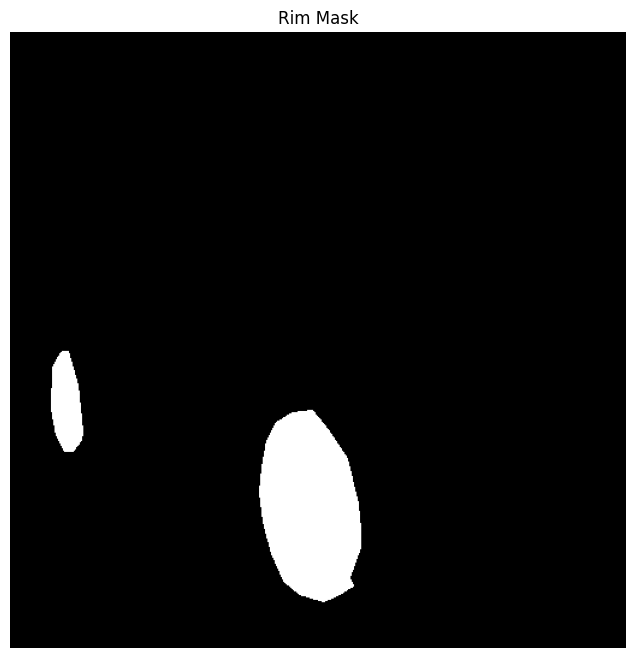

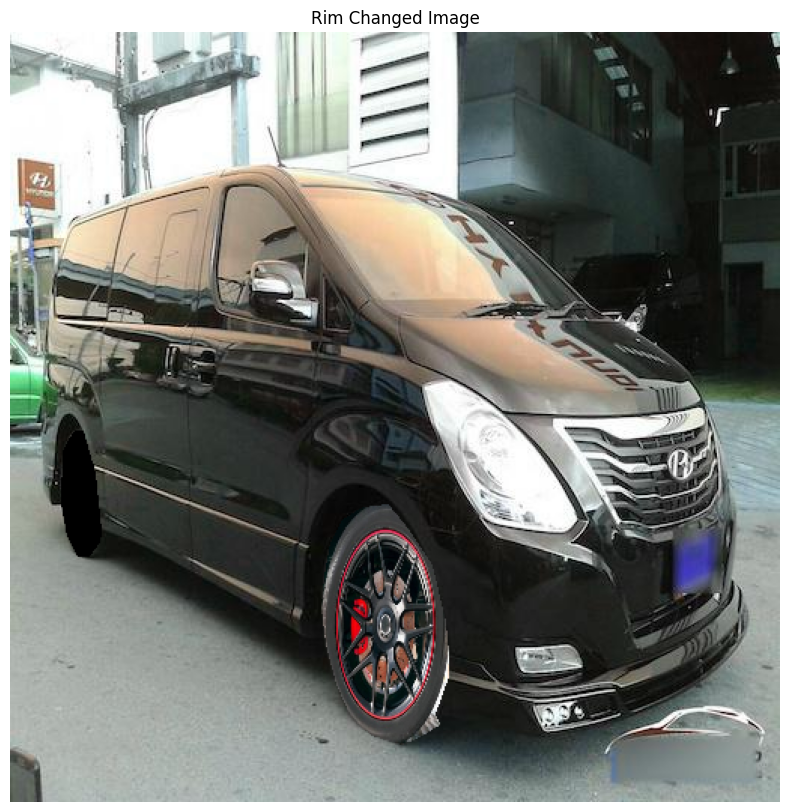

In [39]:

# Initialize COCO and load dataset
data_dir = './testset'
annotation_file = f'{data_dir}/annotations.json'
coco = COCO(annotation_file)

# Get the category ID for rims
rim_category_id = 19

# Load a random image with rim annotations
img_ids = coco.getImgIds(catIds=[rim_category_id])
if not img_ids:
    raise ValueError("No images found with rims.")
random_img_id = img_ids[np.random.randint(len(img_ids))]
img_info = coco.loadImgs(random_img_id)[0]
image_path = f"{data_dir}/{img_info['path']}"
original_image = imread(image_path)

# Get annotations for the selected image
ann_ids = coco.getAnnIds(imgIds=[img_info['id']], catIds=[rim_category_id], iscrowd=None)
anns = coco.loadAnns(ann_ids)

# Create a blank mask
rim_mask = np.zeros((img_info['height'], img_info['width']), dtype=np.uint8)

# Draw the rim masks using segmentation polygons
for ann in anns:
    for seg in ann['segmentation']:
        poly = np.array(seg).reshape((-1, 2))
        cv2.fillPoly(rim_mask, [np.int32(poly)], 255)

# Display the rim mask
plt.figure(figsize=(8, 8))
plt.imshow(rim_mask, cmap='gray')
plt.axis('off')
plt.title("Rim Mask")
plt.show()

# Load new rim image
new_rim_image = cv2.imread("/content/gwagon1.jpg")

# Find contours in the rim mask
contours, _ = cv2.findContours(rim_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
if not contours:
    raise ValueError("No contours found in the rim mask.")

# Get the largest contour (assumes it corresponds to the rim)
rim_contour = max(contours, key=cv2.contourArea)

# Approximate the rim contour to a quadrilateral
epsilon = 0.02 * cv2.arcLength(rim_contour, True)
rim_quad = cv2.approxPolyDP(rim_contour, epsilon, True)

# If not exactly 4 points, fallback to bounding box
if len(rim_quad) != 4:
    x, y, w, h = cv2.boundingRect(rim_contour)
    rim_quad = np.array([
        [[x, y]],
        [[x + w, y]],
        [[x + w, y + h]],
        [[x, y + h]]
    ], dtype=np.float32)
else:
    rim_quad = rim_quad.astype(np.float32)

# Define target points for the new rim image
new_rim_h, new_rim_w = new_rim_image.shape[:2]
new_rim_points = np.array([
    [0, 0],
    [new_rim_w - 1, 0],
    [new_rim_w - 1, new_rim_h - 1],
    [0, new_rim_h - 1]
], dtype=np.float32)

# Compute perspective transform matrix
transform_matrix = cv2.getPerspectiveTransform(new_rim_points, rim_quad.reshape(4, 2))

# Warp the new rim image to the rim mask's region
warped_rim = cv2.warpPerspective(new_rim_image, transform_matrix, (original_image.shape[1], original_image.shape[0]))

# Blend the warped rim into the original image
rim_mask_expanded = cv2.merge([rim_mask] * 3)  # Convert rim mask to 3 channels
blended_image = np.where(rim_mask_expanded > 0, warped_rim, original_image)

# Display the final blended image
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(blended_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Rim Changed Image")
plt.show()


loading annotations into memory...
Done (t=0.03s)
creating index...
index created!


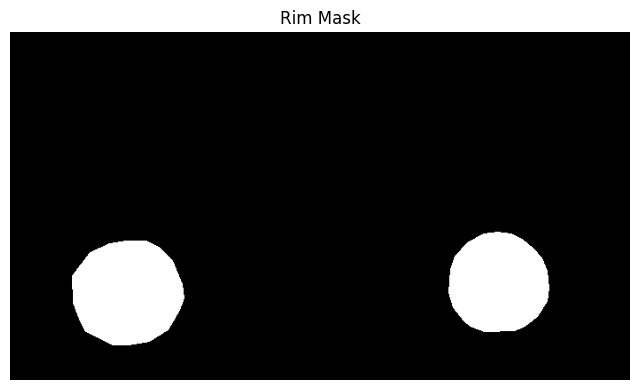

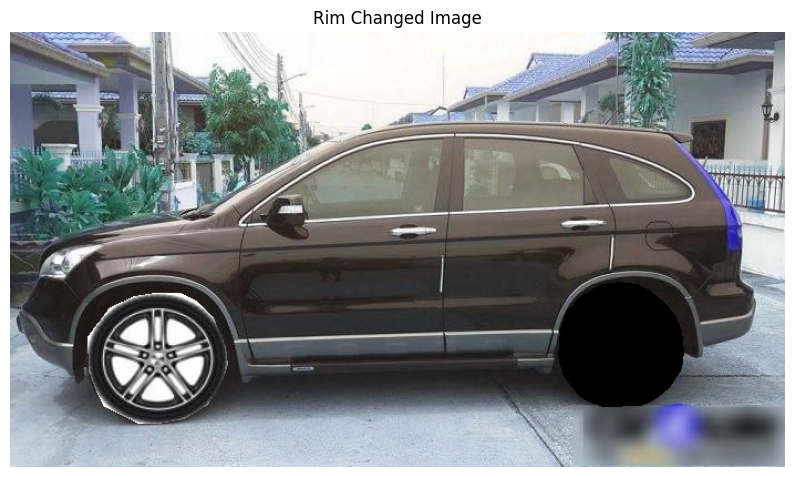

In [40]:

# Initialize COCO and load dataset
data_dir = './testset'
annotation_file = f'{data_dir}/annotations.json'
coco = COCO(annotation_file)

# Get the category ID for rims
rim_category_id = 19

# Load a random image with rim annotations
img_ids = coco.getImgIds(catIds=[rim_category_id])
if not img_ids:
    raise ValueError("No images found with rims.")
random_img_id = img_ids[np.random.randint(len(img_ids))]
img_info = coco.loadImgs(random_img_id)[0]
image_path = f"{data_dir}/{img_info['path']}"
original_image = imread(image_path)

# Get annotations for the selected image
ann_ids = coco.getAnnIds(imgIds=[img_info['id']], catIds=[rim_category_id], iscrowd=None)
anns = coco.loadAnns(ann_ids)

# Create a blank mask
rim_mask = np.zeros((img_info['height'], img_info['width']), dtype=np.uint8)

# Draw the rim masks using segmentation polygons
for ann in anns:
    for seg in ann['segmentation']:
        poly = np.array(seg).reshape((-1, 2))
        cv2.fillPoly(rim_mask, [np.int32(poly)], 255)

# Display the rim mask
plt.figure(figsize=(8, 8))
plt.imshow(rim_mask, cmap='gray')
plt.axis('off')
plt.title("Rim Mask")
plt.show()

# Load new rim image
new_rim_image = cv2.imread("/content/r4.jpg")

# Find contours in the rim mask
contours, _ = cv2.findContours(rim_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
if not contours:
    raise ValueError("No contours found in the rim mask.")

# Get the largest contour (assumes it corresponds to the rim)
rim_contour = max(contours, key=cv2.contourArea)

# Approximate the rim contour to a quadrilateral
epsilon = 0.02 * cv2.arcLength(rim_contour, True)
rim_quad = cv2.approxPolyDP(rim_contour, epsilon, True)

# If not exactly 4 points, fallback to bounding box
if len(rim_quad) != 4:
    x, y, w, h = cv2.boundingRect(rim_contour)
    rim_quad = np.array([
        [[x, y]],
        [[x + w, y]],
        [[x + w, y + h]],
        [[x, y + h]]
    ], dtype=np.float32)
else:
    rim_quad = rim_quad.astype(np.float32)

# Define target points for the new rim image
new_rim_h, new_rim_w = new_rim_image.shape[:2]
new_rim_points = np.array([
    [0, 0],
    [new_rim_w - 1, 0],
    [new_rim_w - 1, new_rim_h - 1],
    [0, new_rim_h - 1]
], dtype=np.float32)

# Compute perspective transform matrix
transform_matrix = cv2.getPerspectiveTransform(new_rim_points, rim_quad.reshape(4, 2))

# Warp the new rim image to the rim mask's region
warped_rim = cv2.warpPerspective(new_rim_image, transform_matrix, (original_image.shape[1], original_image.shape[0]))

# Blend the warped rim into the original image
rim_mask_expanded = cv2.merge([rim_mask] * 3)  # Convert rim mask to 3 channels
blended_image = np.where(rim_mask_expanded > 0, warped_rim, original_image)

# Display the final blended image
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(blended_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Rim Changed Image")
plt.show()


## for all rims

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


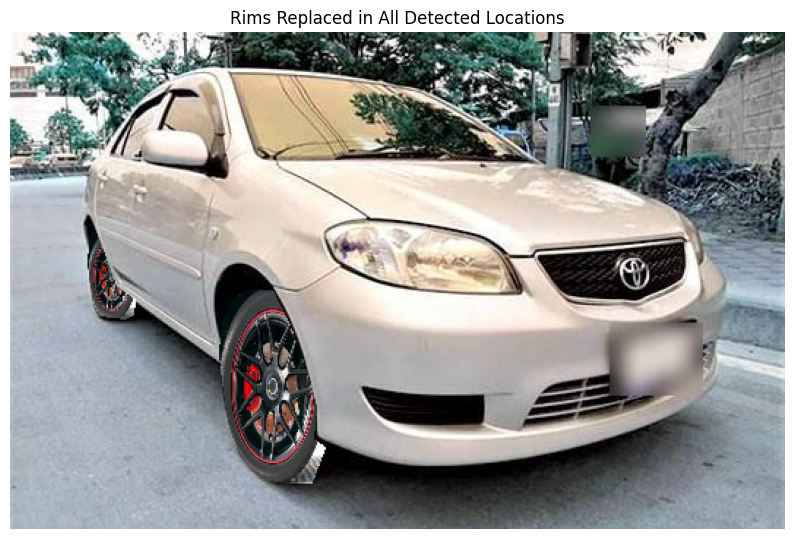

In [45]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
from skimage.io import imread

# Initialize COCO and load dataset
data_dir = './testset'
annotation_file = f'{data_dir}/annotations.json'
coco = COCO(annotation_file)

# Get the category ID for rims
rim_category_id = 19

# Load a random image with rim annotations
img_ids = coco.getImgIds(catIds=[rim_category_id])
if not img_ids:
    raise ValueError("No images found with rims.")

random_img_id = img_ids[np.random.randint(len(img_ids))]
img_info = coco.loadImgs(random_img_id)[0]
image_path = f"{data_dir}/{img_info['path']}"
original_image = imread(image_path)

# Get annotations for the selected image
ann_ids = coco.getAnnIds(imgIds=[img_info['id']], catIds=[rim_category_id], iscrowd=None)
anns = coco.loadAnns(ann_ids)

# Load new rim image
new_rim_image = cv2.imread("/content/gwagon1.jpg")

# Prepare a blank canvas for blending
final_image = original_image.copy()

# Process each rim annotation
for ann in anns:
    # Create a blank mask for the current rim
    rim_mask = np.zeros((img_info['height'], img_info['width']), dtype=np.uint8)
    for seg in ann['segmentation']:
        poly = np.array(seg).reshape((-1, 2))
        cv2.fillPoly(rim_mask, [np.int32(poly)], 255)

    # Find contours in the rim mask
    contours, _ = cv2.findContours(rim_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        print("No contours found for this rim.")
        continue

    # Get the largest contour (assumes it corresponds to the rim)
    rim_contour = max(contours, key=cv2.contourArea)

    # Approximate the rim contour to a quadrilateral
    epsilon = 0.02 * cv2.arcLength(rim_contour, True)
    rim_quad = cv2.approxPolyDP(rim_contour, epsilon, True)

    # If not exactly 4 points, fallback to bounding box
    if len(rim_quad) != 4:
        x, y, w, h = cv2.boundingRect(rim_contour)
        rim_quad = np.array([
            [[x, y]],
            [[x + w, y]],
            [[x + w, y + h]],
            [[x, y + h]]
        ], dtype=np.float32)
    else:
        rim_quad = rim_quad.astype(np.float32)

    # Define target points for the new rim image
    new_rim_h, new_rim_w = new_rim_image.shape[:2]
    new_rim_points = np.array([
        [0, 0],
        [new_rim_w - 1, 0],
        [new_rim_w - 1, new_rim_h - 1],
        [0, new_rim_h - 1]
    ], dtype=np.float32)

    # Compute perspective transform matrix
    transform_matrix = cv2.getPerspectiveTransform(new_rim_points, rim_quad.reshape(4, 2))

    # Warp the new rim image to the rim mask's region
    warped_rim = cv2.warpPerspective(new_rim_image, transform_matrix, (original_image.shape[1], original_image.shape[0]))

    # Blend the warped rim into the original image
    rim_mask_expanded = cv2.merge([rim_mask] * 3)  # Convert rim mask to 3 channels
    final_image = np.where(rim_mask_expanded > 0, warped_rim, final_image)

# Display the final blended image
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(final_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Rims Replaced in All Detected Locations")
plt.show()


loading annotations into memory...
Done (t=0.02s)
creating index...
index created!


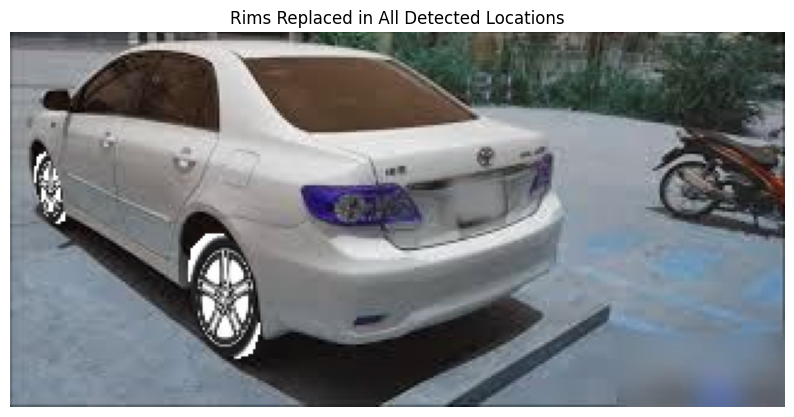

In [49]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
from skimage.io import imread

# Initialize COCO and load dataset
data_dir = './testset'
annotation_file = f'{data_dir}/annotations.json'
coco = COCO(annotation_file)

# Get the category ID for rims
rim_category_id = 19

# Load a random image with rim annotations
img_ids = coco.getImgIds(catIds=[rim_category_id])
if not img_ids:
    raise ValueError("No images found with rims.")

random_img_id = img_ids[np.random.randint(len(img_ids))]
img_info = coco.loadImgs(random_img_id)[0]
image_path = f"{data_dir}/{img_info['path']}"
original_image = imread(image_path)

# Get annotations for the selected image
ann_ids = coco.getAnnIds(imgIds=[img_info['id']], catIds=[rim_category_id], iscrowd=None)
anns = coco.loadAnns(ann_ids)

# Load new rim image
new_rim_image = cv2.imread("/content/r4.jpg")

# Prepare a blank canvas for blending
final_image = original_image.copy()

# Process each rim annotation
for ann in anns:
    # Create a blank mask for the current rim
    rim_mask = np.zeros((img_info['height'], img_info['width']), dtype=np.uint8)
    for seg in ann['segmentation']:
        poly = np.array(seg).reshape((-1, 2))
        cv2.fillPoly(rim_mask, [np.int32(poly)], 255)

    # Find contours in the rim mask
    contours, _ = cv2.findContours(rim_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        print("No contours found for this rim.")
        continue

    # Get the largest contour (assumes it corresponds to the rim)
    rim_contour = max(contours, key=cv2.contourArea)

    # Approximate the rim contour to a quadrilateral
    epsilon = 0.02 * cv2.arcLength(rim_contour, True)
    rim_quad = cv2.approxPolyDP(rim_contour, epsilon, True)

    # If not exactly 4 points, fallback to bounding box
    if len(rim_quad) != 4:
        x, y, w, h = cv2.boundingRect(rim_contour)
        rim_quad = np.array([
            [[x, y]],
            [[x + w, y]],
            [[x + w, y + h]],
            [[x, y + h]]
        ], dtype=np.float32)
    else:
        rim_quad = rim_quad.astype(np.float32)

    # Define target points for the new rim image
    new_rim_h, new_rim_w = new_rim_image.shape[:2]
    new_rim_points = np.array([
        [0, 0],
        [new_rim_w - 1, 0],
        [new_rim_w - 1, new_rim_h - 1],
        [0, new_rim_h - 1]
    ], dtype=np.float32)

    # Compute perspective transform matrix
    transform_matrix = cv2.getPerspectiveTransform(new_rim_points, rim_quad.reshape(4, 2))

    # Warp the new rim image to the rim mask's region
    warped_rim = cv2.warpPerspective(new_rim_image, transform_matrix, (original_image.shape[1], original_image.shape[0]))

    # Blend the warped rim into the original image
    rim_mask_expanded = cv2.merge([rim_mask] * 3)  # Convert rim mask to 3 channels
    final_image = np.where(rim_mask_expanded > 0, warped_rim, final_image)

# Display the final blended image
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(final_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Rims Replaced in All Detected Locations")
plt.show()


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


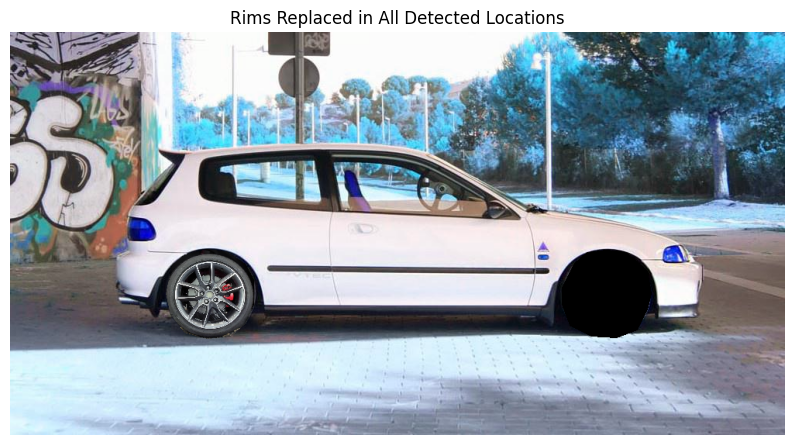

In [51]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
from skimage.io import imread

# Initialize COCO and load dataset
data_dir = './testset'
annotation_file = f'{data_dir}/annotations.json'
coco = COCO(annotation_file)

# Get the category ID for rims
rim_category_id = 19

# Load a random image with rim annotations
img_ids = coco.getImgIds(catIds=[rim_category_id])
if not img_ids:
    raise ValueError("No images found with rims.")

random_img_id = img_ids[np.random.randint(len(img_ids))]
img_info = coco.loadImgs(random_img_id)[0]
image_path = f"{data_dir}/{img_info['path']}"
original_image = imread(image_path)

# Get annotations for the selected image
ann_ids = coco.getAnnIds(imgIds=[img_info['id']], catIds=[rim_category_id], iscrowd=None)
anns = coco.loadAnns(ann_ids)

# Load new rim image
new_rim_image = cv2.imread("/content/aaa.jpg")

# Prepare a blank canvas for blending
final_image = original_image.copy()

# Process each rim annotation
for ann in anns:
    # Create a blank mask for the current rim
    rim_mask = np.zeros((img_info['height'], img_info['width']), dtype=np.uint8)
    for seg in ann['segmentation']:
        poly = np.array(seg).reshape((-1, 2))
        cv2.fillPoly(rim_mask, [np.int32(poly)], 255)

    # Find contours in the rim mask
    contours, _ = cv2.findContours(rim_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        print("No contours found for this rim.")
        continue

    # Get the largest contour (assumes it corresponds to the rim)
    rim_contour = max(contours, key=cv2.contourArea)

    # Approximate the rim contour to a quadrilateral
    epsilon = 0.02 * cv2.arcLength(rim_contour, True)
    rim_quad = cv2.approxPolyDP(rim_contour, epsilon, True)

    # If not exactly 4 points, fallback to bounding box
    if len(rim_quad) != 4:
        x, y, w, h = cv2.boundingRect(rim_contour)
        rim_quad = np.array([
            [[x, y]],
            [[x + w, y]],
            [[x + w, y + h]],
            [[x, y + h]]
        ], dtype=np.float32)
    else:
        rim_quad = rim_quad.astype(np.float32)

    # Define target points for the new rim image
    new_rim_h, new_rim_w = new_rim_image.shape[:2]
    new_rim_points = np.array([
        [0, 0],
        [new_rim_w - 1, 0],
        [new_rim_w - 1, new_rim_h - 1],
        [0, new_rim_h - 1]
    ], dtype=np.float32)

    # Compute perspective transform matrix
    transform_matrix = cv2.getPerspectiveTransform(new_rim_points, rim_quad.reshape(4, 2))

    # Warp the new rim image to the rim mask's region
    warped_rim = cv2.warpPerspective(new_rim_image, transform_matrix, (original_image.shape[1], original_image.shape[0]))

    # Blend the warped rim into the original image
    rim_mask_expanded = cv2.merge([rim_mask] * 3)  # Convert rim mask to 3 channels
    final_image = np.where(rim_mask_expanded > 0, warped_rim, final_image)

# Display the final blended image
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(final_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Rims Replaced in All Detected Locations")
plt.show()


## MOre robust way

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


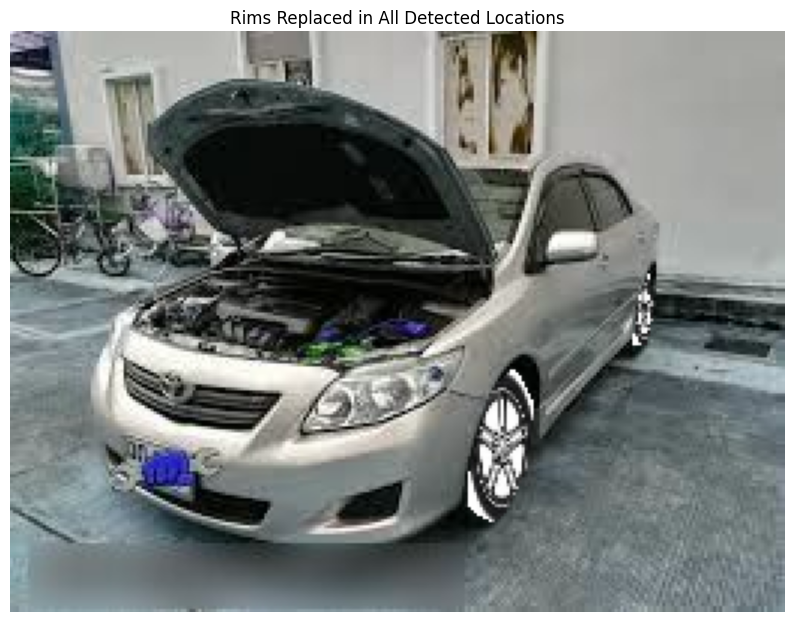

In [58]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
from skimage.io import imread

# Initialize COCO and load dataset
data_dir = './testset'
annotation_file = f'{data_dir}/annotations.json'
coco = COCO(annotation_file)

# Get the category ID for rims
rim_category_id = 19

# Load a random image with rim annotations
img_ids = coco.getImgIds(catIds=[rim_category_id])
if not img_ids:
    raise ValueError("No images found with rims.")

random_img_id = img_ids[np.random.randint(len(img_ids))]
img_info = coco.loadImgs(random_img_id)[0]
image_path = f"{data_dir}/{img_info['path']}"
original_image = imread(image_path)

# Get annotations for the selected image
ann_ids = coco.getAnnIds(imgIds=[img_info['id']], catIds=[rim_category_id], iscrowd=None)
anns = coco.loadAnns(ann_ids)

# Load new rim image
new_rim_image = cv2.imread("/content/r4.jpg")
new_rim_h, new_rim_w = new_rim_image.shape[:2]

# Prepare a blank canvas for blending
final_image = original_image.copy()

# Process each rim annotation
for ann in anns:
    # Create a blank mask for the current rim
    rim_mask = np.zeros((img_info['height'], img_info['width']), dtype=np.uint8)
    for seg in ann['segmentation']:
        poly = np.array(seg).reshape((-1, 2))
        cv2.fillPoly(rim_mask, [np.int32(poly)], 255)

    # Find contours in the rim mask
    contours, _ = cv2.findContours(rim_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        print("No contours found for this rim.")
        continue

    # Process each contour found (multiple rims)
    for contour in contours:
        # Approximate the rim contour to a quadrilateral
        epsilon = 0.02 * cv2.arcLength(contour, True)
        rim_quad = cv2.approxPolyDP(contour, epsilon, True)

        # If not exactly 4 points, fallback to bounding box
        if len(rim_quad) != 4:
            x, y, w, h = cv2.boundingRect(contour)
            rim_quad = np.array([
                [x, y],
                [x + w, y],
                [x + w, y + h],
                [x, y + h]
            ], dtype=np.float32)
        else:
            rim_quad = rim_quad.astype(np.float32)

        # Define target points for the new rim image
        new_rim_points = np.array([
            [0, 0],
            [new_rim_w - 1, 0],
            [new_rim_w - 1, new_rim_h - 1],
            [0, new_rim_h - 1]
        ], dtype=np.float32)

        # Compute perspective transform matrix
        try:
            transform_matrix = cv2.getPerspectiveTransform(new_rim_points, rim_quad)

            # Warp the new rim image to the rim mask's region
            warped_rim = cv2.warpPerspective(new_rim_image, transform_matrix, (original_image.shape[1], original_image.shape[0]))

            # Create an expanded mask to match the 3-channel image
            rim_mask_expanded = cv2.merge([rim_mask] * 3)  # Convert rim mask to 3 channels

            # Blend the warped rim into the original image
            final_image = np.where(rim_mask_expanded > 0, warped_rim, final_image)

        except cv2.error as e:
            print(f"Error in perspective transformation: {e}")
            continue

# Display the final blended image
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(final_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Rims Replaced in All Detected Locations")
plt.show()


c:\Users\92323\Desktop\FYP working\Notebooks\Car Part segmentation\Car-Parts-Segmentation\Car-Parts-Segmentation
loading annotations into memory...
Done (t=0.03s)
creating index...
index created!


Cloning into 'Car-Parts-Segmentation'...


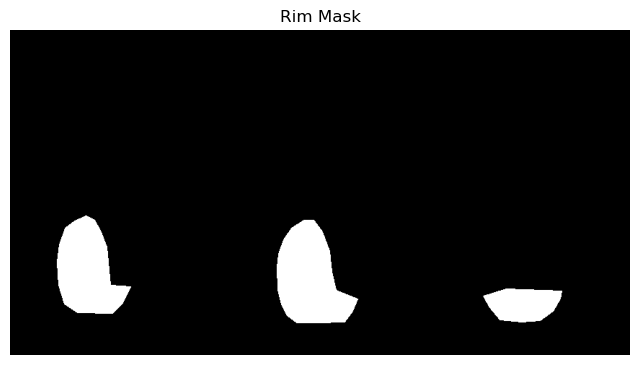

AttributeError: 'NoneType' object has no attribute 'shape'

In [2]:
!git clone https://github.com/dsmlr/Car-Parts-Segmentation.git
%cd Car-Parts-Segmentation

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2
from pycocotools.coco import COCO
from scipy.spatial import ConvexHull
import skimage.io as io

# Initialize COCO and load dataset
data_dir = './testset'
annotation_file = f'{data_dir}/annotations.json'
coco = COCO(annotation_file)

# Get the category ID for rims
rim_category_id = 19

# Load a random image with rim annotations
img_ids = coco.getImgIds(catIds=[rim_category_id])
if not img_ids:
    raise ValueError("No images found with rims.")
random_img_id = img_ids[np.random.randint(len(img_ids))]
img_info = coco.loadImgs(random_img_id)[0]
image_path = f"{data_dir}/{img_info['path']}"
original_image = io.imread(image_path)

# Get annotations for the selected image
ann_ids = coco.getAnnIds(imgIds=[img_info['id']], catIds=[rim_category_id], iscrowd=None)
anns = coco.loadAnns(ann_ids)

# Create a blank mask
rim_mask = np.zeros((img_info['height'], img_info['width']), dtype=np.uint8)

# Draw the rim masks using segmentation polygons
for ann in anns:
    for seg in ann['segmentation']:
        poly = np.array(seg).reshape((-1, 2))
        cv2.fillPoly(rim_mask, [np.int32(poly)], 255)

# Display the rim mask
plt.figure(figsize=(8, 8))
plt.imshow(rim_mask, cmap='gray')
plt.axis('off')
plt.title("Rim Mask")
plt.show()

# Load the new rim design image
new_rim_image = cv2.imread('Car Part segmentation\rims images\gwagon1.jpg')

# Find contours in the rim mask
contours, _ = cv2.findContours(rim_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
if not contours:
    raise ValueError("No contours found in the rim mask.")

# Get the largest contour (assumes it corresponds to the rim)
rim_contour = max(contours, key=cv2.contourArea)

# Approximate the rim contour to a quadrilateral
epsilon = 0.02 * cv2.arcLength(rim_contour, True)
rim_quad = cv2.approxPolyDP(rim_contour, epsilon, True)

# If not exactly 4 points, fallback to bounding box
if len(rim_quad) != 4:
    x, y, w, h = cv2.boundingRect(rim_contour)
    rim_quad = np.array([
        [[x, y]],
        [[x + w, y]],
        [[x + w, y + h]],
        [[x, y + h]]
    ], dtype=np.float32)
else:
    rim_quad = rim_quad.astype(np.float32)

# Define target points for the new rim image
new_rim_h, new_rim_w = new_rim_image.shape[:2]
new_rim_points = np.array([
    [0, 0],
    [new_rim_w - 1, 0],
    [new_rim_w - 1, new_rim_h - 1],
    [0, new_rim_h - 1]
], dtype=np.float32)

# Compute perspective transform matrix
transform_matrix = cv2.getPerspectiveTransform(new_rim_points, rim_quad.reshape(4, 2))

# Warp the new rim image to the rim mask's region
warped_rim = cv2.warpPerspective(new_rim_image, transform_matrix, (original_image.shape[1], original_image.shape[0]))

# Blend the warped rim into the original image
rim_mask_expanded = cv2.merge([rim_mask] * 3)  # Convert rim mask to 3 channels
blended_image = np.where(rim_mask_expanded > 0, warped_rim, original_image)

# Display the final blended image
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(blended_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Rim Changed Image")
plt.show()
